In [86]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [87]:
class Signal:
    """
    Classe Signal qui permet de charger et de visualiser les données météorologiques de Strasbourg Entzheim.
    """

    def __init__(self) -> None:

        self.__file_path = (
            Path.cwd() / ".." / "data" / "strasbourg_entzheim.csv"
        ).resolve()

        self.__df = pd.read_csv(filepath_or_buffer=self.__file_path, sep=",")

        # température moyenne
        self.tavg = self.__df["tavg"].to_numpy()

        # température minimum
        self.tmin = self.__df["tmin"].to_numpy()

        # température maximum
        self.tmax = self.__df["tmax"].to_numpy()

        # taux de précipitation
        self.prcp = self.__df["prcp"].to_numpy()

        # taux de neige
        self.snow = self.__df["snow"].to_numpy()

        # direction du vent
        self.wdir = self.__df["wdir"].to_numpy()

        # vitesse du vent (en km/h)
        self.wspd = self.__df["wspd"].to_numpy()

        # pic de rafale (en km/h)
        self.wpgt = self.__df["wpgt"].to_numpy()

        # pression atmosphérique (en hPa)
        self.pres = self.__df["pres"].to_numpy()

        # durée d’ensoleillement (en minutes)
        self.tsun = self.__df["tsun"].to_numpy()

        self.__data = {
            "tavg": (self.tavg, "°C"),
            "tmin": (self.tmin, "°C"),
            "tmax": (self.tmax, "°C"),
            "prcp": (self.prcp, "mm"),
            "snow": (self.snow, "mm"),
            "wdir": (self.wdir, "°"),
            "wspd": (self.wspd, "km/h"),
            "wpgt": (self.wpgt, "km/h"),
            "pres": (self.pres, "hPa"),
            "tsun": (self.tsun, "min"),
        }

    def __check_data(self, donnée: str | tuple) -> None:
        """Vérifie si la donnée est valide

        Args:
            donnée (str | tuple): Nom de la donnée à vérifier.

        Raises:
            ValueError: Si la donnée n'est pas valide.
        """

        if isinstance(donnée, tuple):
            for d in donnée:
                if d not in self.__data:
                    raise ValueError(f"{d} n'est pas une donnée valide.")
        else:
            if donnée not in self.__data:
                raise ValueError(f"{donnée} n'est pas une donnée valide.")

    def plot_signal(self, donnée: str | tuple, start: int = 0, end: int = 365) -> None:
        """Génère le plot d'un ou plusieurs signal

        Args:
            donnée (str | tuple): Nom de la donnée ou tuple de noms de données à afficher.
            start (int, optional): Index de départ. Defaults to 0.
            end (int, optional): Index d'arrivée. Defaults to 365.

        Raises:
            ValueError: Si la donnée n'est pas valide.
        """

        données = donnée if isinstance(donnée, tuple) else (donnée,)

        self.__check_data(données)

        plt.figure(figsize=(10, 5))

        for d in données:
            valeurs, unité = self.__data[d]
            x = np.asarray(valeurs[start:end], dtype=float)

            plt.plot(x, label=f"{d} ({unité})")

        plt.title(" / ".join(données))

        plt.xlabel("Temps (jours)")
        plt.ylabel("Valeur")

        plt.grid()
        plt.legend()

        plt.show()

    def signal_data(
        self, donnée: str, start: int = 0, end: int = 365
    ) -> tuple[np.ndarray, np.ndarray, str, np.ndarray, float]:
        """Retourne les données d'un signal

        Args:
            donnée (str): Nom de la donnée à afficher.
            start (int, optional): Index de départ. Defaults to 0.
            end (int, optional): Index d'arrivée. Defaults to 365.

        Raises:
            ValueError: Si la donnée n'est pas valide.
        """
        self.__check_data(donnée)

        valeurs, unite = self.__data[donnée]

        x = np.asarray(valeurs[start:end], dtype=float)

        len_x = len(x)

        if np.isnan(
            x
        ).all():  # Check si les données contiennent que des valeurs manquantes
            raise ValueError(f"Les données de {donnée} contiennent aucune valeur.")

        if np.isnan(x).any():
            x = (
                pd.Series(x).interpolate(limit_direction="both").to_numpy()
            )  # On remplace les valeurs manquantes par interpolation linéaire ( on prend le plus proche voisin pour les valeurs manquantes au début et à la fin )

        amp = (
            np.abs(np.fft.rfft(x)) * 2 / len_x
        )  # On calcule l'amplitude de la transformée de Fourier et on la normalise

        fft_freq = np.fft.rfftfreq(len_x, d=1)

        phase = np.angle(
            np.fft.rfft(x)
        )  # On calcule la phase de la transformée de Fourier

        return (
            amp[1 : len(amp)],
            fft_freq[1 : len(amp)],
            unite,
            phase[1 : len(amp)],
            float(x.mean()),
        )  # On retourne l'amplitude, la fréquence, l'unité, la phase du signal et la valeur moyenne du signal

    def spectrum(self, donnée: str, start: int = 0, end: int = 365) -> None:
        """Génère le spectre d'un signal

        Args:
            donnée (str): Nom de la donnée à afficher.
            start (int, optional): Index de départ. Defaults to 0.
            end (int, optional): Index d'arrivée. Defaults to 365.

        Raises:
            ValueError: Si la donnée n'est pas valide.
        """

        amp, fft_freq, unite, _, _ = self.signal_data(donnée, start, end)

        plt.figure(figsize=(10, 5))

        plt.stem(fft_freq[: len(amp)], amp, markerfmt=" ", basefmt=" ")

        plt.title(f"Spectre de {donnée} ({unite})")

        plt.xlabel("Fréquence (cycles/jour)")
        plt.ylabel("Amplitude")

        plt.grid()
        plt.show()

    def reconstruct_signal(
        self,
        donnée: str,
        start: int = 0,
        end: int = 365,
        n_harmonics: int = 10,
        plot: bool = False,
        filter: bool = False,
    ) -> np.ndarray | None:
        """Reconstruit le signal à partir de ses n premières harmoniques

        Args:
            donnée (str): Nom de la donnée à reconstruire.
            start (int, optional): Index de départ. Defaults to 0.
            end (int, optional): Index d'arrivée. Defaults to 365.
            n_harmonics (int, optional): Nombre d'harmoniques à utiliser pour la reconstruction. Defaults to 10.

        Raises:
            ValueError: Si la donnée n'est pas valide.
        """

        amp, fft_freq, unite, phase, mean_value = self.signal_data(donnée, start, end)

        signal = np.zeros(
            len(amp) * 2, dtype=float
        )  # On initialise le signal à reconstruire

        n_harmonics = min(
            n_harmonics, len(amp)
        )  # On s'assure de ne pas dépasser le nombre d'harmoniques disponibles

        signal += mean_value  # On ajoute la valeur moyenne du signal

        t = np.arange(len(amp) * 2, dtype=float)

        for i in range(n_harmonics):
            signal += amp[i] * np.cos(2 * np.pi * fft_freq[i] * t + phase[i])

        if plot:
            plt.figure(figsize=(10, 5))

            plt.plot(
                self.__data[donnée][0][start:end],
                label=f"Signal original de {donnée} ({unite})",
                alpha=0.3,
                color="red",
            )

            plt.plot(
                signal,
                label=f"Signal reconstruit avec {n_harmonics} harmoniques",
                color="black",
            )

            plt.title(f"Signal reconstruit de {donnée} ({unite})")

            plt.xlabel("Temps (jours)")
            plt.ylabel("Valeur")

            plt.grid()

            plt.legend()

            plt.show()

        else:
            return signal

    def filter_signal(
        self, donnée: str, start: int = 0, end: int = 365, M: int = 7
    ) -> np.ndarray:
        """Filtre le signal à partir de ses n premières harmoniques

        Args:
            donnée (str): Nom de la donnée à filtrer.
            start (int): Index de départ.
            end (int): Index d'arrivée.
            M (int): Paramètre de filtrage.
        Raises:
            ValueError: Si la donnée n'est pas valide.
        """

        self.__check_data(donnée)

        valeurs, _ = self.__data[donnée]

        x = np.asarray(valeurs[start:end], dtype=float)

        len_x = len(x)

        if np.isnan(
            x
        ).all():  # Check si les données contiennent que des valeurs manquantes
            raise ValueError(f"Les données de {donnée} contiennent aucune valeur.")

        if np.isnan(x).any():
            x = (
                pd.Series(x).interpolate(limit_direction="both").to_numpy()
            )  # On remplace les valeurs manquantes par interpolation linéaire ( on prend le plus proche voisin pour les valeurs manquantes au début et à la fin )

        fft_freq = np.fft.rfftfreq(len_x, d=1)

        h = np.zeros(len(fft_freq), dtype=complex)

        for i in range(len(fft_freq)):
            f = fft_freq[i]
            if f == 0:
                h[i] = 1
            else:
                h[i] = np.exp(-1j * np.pi * f*(M - 1)) * (
                    np.sin(np.pi * M * f) / (M * np.sin(np.pi * f))
                )

        X = np.fft.rfft(x)
        H = h
        Y = X * H

        y = np.fft.irfft(Y, n=len_x)

        plt.figure(figsize=(10, 5))
        plt.plot(x, label=f"Signal original de {donnée}", alpha=0.3, color="red")
        plt.plot(y, label=f"Signal filtré de {donnée} avec M={M}", color="black")
        plt.title(f"Signal filtré de {donnée}")
        plt.xlabel("Temps (jours)")
        plt.ylabel("Valeur")
        plt.grid()
        plt.legend()
        plt.show()

        return y


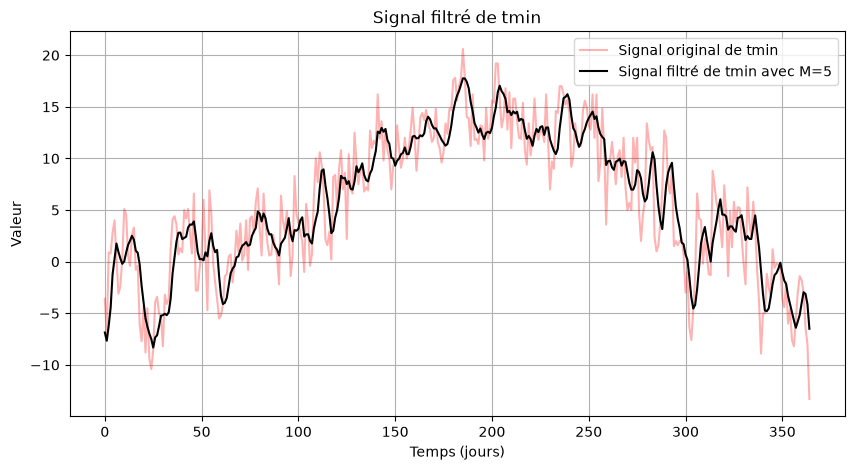

array([-6.86, -7.66, -6.2 , -4.44, -1.22,  0.3 ,  1.76,  0.96,  0.32,
       -0.2 ,  0.02,  0.88,  1.62,  2.02,  2.5 ,  2.14,  1.06,  0.86,
       -0.28, -2.34, -3.88, -5.48, -6.3 , -6.96, -7.5 , -8.32, -7.34,
       -7.12, -6.24, -5.24, -5.18, -5.04, -5.18, -4.9 , -3.58, -1.12,
        0.4 ,  1.94,  2.8 ,  2.82,  2.18,  2.3 ,  2.42,  3.3 ,  3.6 ,
        3.58,  3.9 ,  2.5 ,  0.92,  0.24,  0.26,  0.14,  0.9 ,  0.52,
        2.02,  2.76,  1.52,  0.92,  1.14, -1.34, -3.3 , -4.1 , -3.98,
       -3.5 , -2.3 , -1.12, -0.68, -0.42,  0.42,  0.52,  1.12,  1.54,
        1.7 ,  1.9 ,  1.54,  1.64,  2.5 ,  2.92,  3.28,  4.86,  4.66,
        3.9 ,  4.66,  4.22,  3.16,  2.64,  2.66,  1.86,  1.42,  1.16,
        0.6 ,  1.74,  2.02,  2.32,  3.2 ,  4.22,  2.66,  1.98,  3.06,
        3.  ,  3.18,  4.02,  4.3 ,  2.44,  2.64,  2.66,  2.02,  1.76,
        3.22,  4.1 ,  4.86,  7.06,  8.8 ,  8.94,  7.36,  6.14,  4.6 ,
        2.76,  3.  ,  4.26,  4.98,  6.2 ,  8.32,  8.08,  8.12,  7.52,
        7.8 ,  7.06,

In [88]:
test = Signal()

# ampl, freq, unit, phase, mean_value = test.signal_data("prcp", start=0, end=22_000)

# test.reconstruct_signal("tavg", start=0, end=365, n_harmonics=100, plot=True)

test.filter_signal("tmin", M=5)
